In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
demographics = pd.read_csv("Demographics_SD_ZipCode.csv", dtype={"Zip Code": str})

In [3]:
assistance = pd.read_csv("Assistance_Integrated.csv")

In [4]:
demographics.head(5)

,Zip Code,Total_Population,Total_Households,Family_Households,Nonfamily_Households,Householder_Living_Alone,Single_Father_Households_With_Own_Children_Under18,Single_Mother_Households_With_Own_Children_Under18,Median_Gross_Rent,Median_Monthly_Owner_Cost_With_Mortgage,...,Population_Under_18,Population_18_to_64,Population_65_Plus,Poverty_Rate_Pct,Unemployment_Rate_Pct,ACS_Vintage_Start_Year,ACS_Vintage_End_Year,Subject_Table_Available,Data_Year,Has_Missing_Demographic_Data
0,91901,18558,6411,4683,1728,1539,137,354,1465.0,2736.0,...,4220,11115,3223,8.5,4.2,2014,2018,True,2018,False
1,91901,18162,6320,4576,1744,1620,196,300,1622.0,2841.0,...,4195,10789,3178,NaN,NaN,2015,2019,False,2019,True
2,91901,17896,6150,4584,1566,1448,164,233,1686.0,2831.0,...,3866,10980,3050,7.1,6.4,2016,2020,True,2020,False
3,91901,18367,6313,4766,1547,1335,199,183,1768.0,2900.0,...,4039,11186,3142,8.8,6.9,2017,2021,True,2021,False
4,91901,18669,6425,4793,1632,1241,215,167,1963.0,3034.0,...,3982,11566,3121,8.8,6.3,2018,2022,True,2022,False


In [5]:
assistance.head(5)

,Zip Code,Month Year,Calfresh_Dollars,Calfresh_Meal_Cost,Calfresh_Meals,Calfresh_Outlier,LIHEAP_Enrollment_Count,LIHEAP_Outlier,FSD_Pounds,SDFB_Pounds,Total_Pounds_Distributed,FoodBank_Outlier
0,91901,2018-01,NaN,NaN,NaN,NaN,NaN,NaN,7884.0,0.0,7884.0,False
1,91901,2018-02,NaN,NaN,NaN,NaN,NaN,NaN,10558.0,0.0,10558.0,False
2,91901,2018-03,NaN,NaN,NaN,NaN,NaN,NaN,10642.0,0.0,10642.0,False
3,91901,2018-04,NaN,NaN,NaN,NaN,NaN,NaN,12192.0,0.0,12192.0,False
4,91901,2018-05,NaN,NaN,NaN,NaN,NaN,NaN,10370.0,0.0,10370.0,False


**Perform standaidization on the join keys**

In [6]:
assistance["Zip Code"] = assistance["Zip Code"].astype(str).str.zfill(5)
assistance["Date_Year"] = pd.to_datetime(assistance["Month Year"], format="%Y-%m").dt.year


In [7]:
demographics = demographics.rename(columns={"Data_Year": "Date_Year"})
demographics.head(5)

,Zip Code,Total_Population,Total_Households,Family_Households,Nonfamily_Households,Householder_Living_Alone,Single_Father_Households_With_Own_Children_Under18,Single_Mother_Households_With_Own_Children_Under18,Median_Gross_Rent,Median_Monthly_Owner_Cost_With_Mortgage,...,Population_Under_18,Population_18_to_64,Population_65_Plus,Poverty_Rate_Pct,Unemployment_Rate_Pct,ACS_Vintage_Start_Year,ACS_Vintage_End_Year,Subject_Table_Available,Date_Year,Has_Missing_Demographic_Data
0,91901,18558,6411,4683,1728,1539,137,354,1465.0,2736.0,...,4220,11115,3223,8.5,4.2,2014,2018,True,2018,False
1,91901,18162,6320,4576,1744,1620,196,300,1622.0,2841.0,...,4195,10789,3178,NaN,NaN,2015,2019,False,2019,True
2,91901,17896,6150,4584,1566,1448,164,233,1686.0,2831.0,...,3866,10980,3050,7.1,6.4,2016,2020,True,2020,False
3,91901,18367,6313,4766,1547,1335,199,183,1768.0,2900.0,...,4039,11186,3142,8.8,6.9,2017,2021,True,2021,False
4,91901,18669,6425,4793,1632,1241,215,167,1963.0,3034.0,...,3982,11566,3121,8.8,6.3,2018,2022,True,2022,False


**Merge Both Datasets on Zip Code**
- perform left join using assistance as the base and dempgrahics as the dataset being merged on that
- left join was recommnended to keep every row in the assistance panel and fill in the dempgraihc columns where a match exists
- leave null values where it doesn't

In [8]:
merged = assistance.merge(demographics, on=['Zip Code', 'Date_Year'], how='left')

In [9]:
merged.head(5)

,Zip Code,Month Year,Calfresh_Dollars,Calfresh_Meal_Cost,Calfresh_Meals,Calfresh_Outlier,LIHEAP_Enrollment_Count,LIHEAP_Outlier,FSD_Pounds,SDFB_Pounds,...,Median_Monthly_Owner_Cost_No_Mortgage,Population_Under_18,Population_18_to_64,Population_65_Plus,Poverty_Rate_Pct,Unemployment_Rate_Pct,ACS_Vintage_Start_Year,ACS_Vintage_End_Year,Subject_Table_Available,Has_Missing_Demographic_Data
0,91901,2018-01,NaN,NaN,NaN,NaN,NaN,NaN,7884.0,0.0,...,709.0,4220.0,11115.0,3223.0,8.5,4.2,2014.0,2018.0,True,False
1,91901,2018-02,NaN,NaN,NaN,NaN,NaN,NaN,10558.0,0.0,...,709.0,4220.0,11115.0,3223.0,8.5,4.2,2014.0,2018.0,True,False
2,91901,2018-03,NaN,NaN,NaN,NaN,NaN,NaN,10642.0,0.0,...,709.0,4220.0,11115.0,3223.0,8.5,4.2,2014.0,2018.0,True,False
3,91901,2018-04,NaN,NaN,NaN,NaN,NaN,NaN,12192.0,0.0,...,709.0,4220.0,11115.0,3223.0,8.5,4.2,2014.0,2018.0,True,False
4,91901,2018-05,NaN,NaN,NaN,NaN,NaN,NaN,10370.0,0.0,...,709.0,4220.0,11115.0,3223.0,8.5,4.2,2014.0,2018.0,True,False


In [10]:
merged.dtypes

Zip Code                                                  str
Month Year                                                str
Calfresh_Dollars                                      float64
Calfresh_Meal_Cost                                    float64
Calfresh_Meals                                        float64
Calfresh_Outlier                                       object
LIHEAP_Enrollment_Count                               float64
LIHEAP_Outlier                                         object
FSD_Pounds                                            float64
SDFB_Pounds                                           float64
Total_Pounds_Distributed                              float64
FoodBank_Outlier                                       object
Date_Year                                               int32
Total_Population                                      float64
Total_Households                                      float64
Family_Households                                     float64
Nonfamil

In [11]:
merged = merged.astype({
    "LIHEAP_Enrollment_Count": "Int64",
    "Total_Population": "Int64",
    "Total_Households": "Int64",
    "Family_Households": "Int64",
    "Nonfamily_Households": "Int64",
    "Single_Father_Households_With_Own_Children_Under18": "Int64",
    "Single_Mother_Households_With_Own_Children_Under18": "Int64",
    "Median_Gross_Rent": "Int64",
    "Median_Monthly_Owner_Cost_With_Mortgage": "Int64",
    "Median_Monthly_Owner_Cost_No_Mortgage": "Int64",
    "Population_Under_18": "Int64",
    "Population_18_to_64": "Int64",
    "Population_65_Plus": "Int64",
    "ACS_Vintage_Start_Year": "Int32",
    "ACS_Vintage_End_Year": "Int32"
})

**Convert outlier flags without turning blanks into true**
- `astype(bool)` treats a blank (NaN) as True, so every month with no CalFresh, LIHEAP or food bank data was flagged as an outlier
- use the nullable `boolean` type instead, so the flags are True, False, or blank (`<NA>`)
- a row with none of a program's data gets a blank flag, because there is nothing to call an outlier

In [12]:
flag_sources = {
    "Calfresh_Outlier": ["Calfresh_Dollars", "Calfresh_Meal_Cost", "Calfresh_Meals"],
    "LIHEAP_Outlier": ["LIHEAP_Enrollment_Count"],
    "FoodBank_Outlier": ["FSD_Pounds", "SDFB_Pounds", "Total_Pounds_Distributed"],
}

for flag, source_cols in flag_sources.items():
    merged[flag] = merged[flag].astype("boolean")      # True / False / <NA>, NaN stays <NA>
    no_data = merged[source_cols].isna().all(axis=1)
    merged.loc[no_data, flag] = pd.NA                  # no data -> no outlier verdict

    # check: no row without data may be flagged as an outlier
    assert not merged.loc[no_data, flag].fillna(False).any(), f"{flag} is True on rows with no data"
    print(f"{flag}: {merged[flag].value_counts(dropna=False).to_dict()}")

Calfresh_Outlier: {np.False_: 9932, <NA>: 2725, np.True_: 941}
LIHEAP_Outlier: {<NA>: 13020, np.False_: 543, np.True_: 35}
FoodBank_Outlier: {np.False_: 8272, <NA>: 4214, np.True_: 1112}


**Drop columns ACS_Vintage_Start_Year, ACS_Vintage_End_Year, Subject_Table_Available, Has_Missing_Demographic_Data**

In [13]:
columns_to_be_cut = ["ACS_Vintage_Start_Year", "ACS_Vintage_End_Year", "Subject_Table_Available", "Has_Missing_Demographic_Data"]

In [14]:
merged = merged.drop(columns=columns_to_be_cut)

**Drop Rows where FSD Pounds is Less Than 0**
 - bad data, should not be included in the final dataset

In [15]:
indices_to_drop = merged[merged["FSD_Pounds"] < 0].index
merged = merged.drop(index=indices_to_drop)
merged

,Zip Code,Month Year,Calfresh_Dollars,Calfresh_Meal_Cost,Calfresh_Meals,Calfresh_Outlier,LIHEAP_Enrollment_Count,LIHEAP_Outlier,FSD_Pounds,SDFB_Pounds,...,Single_Father_Households_With_Own_Children_Under18,Single_Mother_Households_With_Own_Children_Under18,Median_Gross_Rent,Median_Monthly_Owner_Cost_With_Mortgage,Median_Monthly_Owner_Cost_No_Mortgage,Population_Under_18,Population_18_to_64,Population_65_Plus,Poverty_Rate_Pct,Unemployment_Rate_Pct
0,91901,2018-01,NaN,NaN,NaN,<NA>,<NA>,<NA>,7884.0,0.0,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
1,91901,2018-02,NaN,NaN,NaN,<NA>,<NA>,<NA>,10558.0,0.0,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
2,91901,2018-03,NaN,NaN,NaN,<NA>,<NA>,<NA>,10642.0,0.0,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
3,91901,2018-04,NaN,NaN,NaN,<NA>,<NA>,<NA>,12192.0,0.0,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
4,91901,2018-05,NaN,NaN,NaN,<NA>,<NA>,<NA>,10370.0,0.0,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13593,92198,2025-04,7966.02,4.625089,1722.349671,False,<NA>,<NA>,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN
13594,92198,2025-05,9157.02,4.653009,1967.978089,False,<NA>,<NA>,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN
13595,92198,2025-06,10087.03,4.631940,2177.711556,False,<NA>,<NA>,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN
13596,92198,2025-07,9229.00,4.725154,1953.163959,False,<NA>,<NA>,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN


**Check for duplicate zip code**
- no duplication

In [16]:
is_duplicate_row = merged.duplicated(subset=["Zip Code", "Month Year"])
print(is_duplicate_row.value_counts())

False    13596
Name: count, dtype: int64


In [17]:
print(merged.isna().sum())

Zip Code                                                  0
Month Year                                                0
Calfresh_Dollars                                       2724
Calfresh_Meal_Cost                                     2724
Calfresh_Meals                                         2724
Calfresh_Outlier                                       2724
LIHEAP_Enrollment_Count                               13018
LIHEAP_Outlier                                        13018
FSD_Pounds                                             4214
SDFB_Pounds                                            5778
Total_Pounds_Distributed                               4214
FoodBank_Outlier                                       4214
Date_Year                                                 0
Total_Population                                       4138
Total_Households                                       4138
Family_Households                                      4138
Nonfamily_Households                    

In [18]:
(merged.isna().sum() / len(merged)) * 100

Zip Code                                               0.000000
Month Year                                             0.000000
Calfresh_Dollars                                      20.035305
Calfresh_Meal_Cost                                    20.035305
Calfresh_Meals                                        20.035305
Calfresh_Outlier                                      20.035305
LIHEAP_Enrollment_Count                               95.748750
LIHEAP_Outlier                                        95.748750
FSD_Pounds                                            30.994410
SDFB_Pounds                                           42.497793
Total_Pounds_Distributed                              30.994410
FoodBank_Outlier                                      30.994410
Date_Year                                              0.000000
Total_Population                                      30.435422
Total_Households                                      30.435422
Family_Households                       

In [19]:
merged = merged.reset_index(drop=True)

In [20]:
merged.to_csv('Assistance_Demographics_Master.csv', index=False)

In [21]:
merged[["Poverty_Rate_Pct"]].describe()

,Poverty_Rate_Pct
count,7906.000000
mean,11.597243
std,8.724410
min,0.000000
25%,6.600000
50%,9.700000
75%,13.800000
max,93.500000


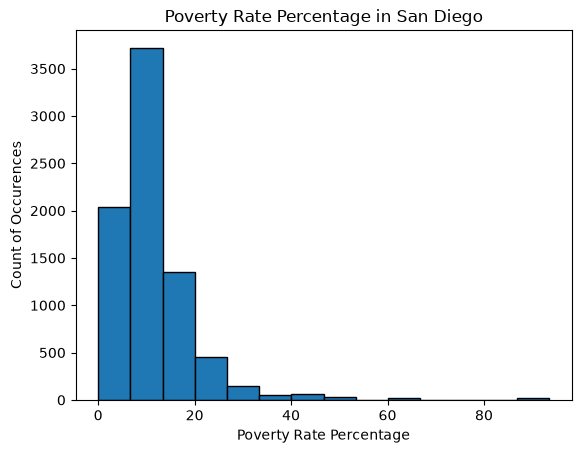

In [22]:
plt.hist(data=merged, x="Poverty_Rate_Pct", bins=14, edgecolor="black")
plt.xlabel("Poverty Rate Percentage")
plt.ylabel("Count of Occurences")
plt.title("Poverty Rate Percentage in San Diego")
plt.show()

In [23]:
merged_poverty = merged[merged["Poverty_Rate_Pct"] > 0]
merged_poverty

,Zip Code,Month Year,Calfresh_Dollars,Calfresh_Meal_Cost,Calfresh_Meals,Calfresh_Outlier,LIHEAP_Enrollment_Count,LIHEAP_Outlier,FSD_Pounds,SDFB_Pounds,...,Single_Father_Households_With_Own_Children_Under18,Single_Mother_Households_With_Own_Children_Under18,Median_Gross_Rent,Median_Monthly_Owner_Cost_With_Mortgage,Median_Monthly_Owner_Cost_No_Mortgage,Population_Under_18,Population_18_to_64,Population_65_Plus,Poverty_Rate_Pct,Unemployment_Rate_Pct
0,91901,2018-01,NaN,NaN,NaN,<NA>,<NA>,<NA>,7884.0,0.000000,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
1,91901,2018-02,NaN,NaN,NaN,<NA>,<NA>,<NA>,10558.0,0.000000,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
2,91901,2018-03,NaN,NaN,NaN,<NA>,<NA>,<NA>,10642.0,0.000000,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
3,91901,2018-04,NaN,NaN,NaN,<NA>,<NA>,<NA>,12192.0,0.000000,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
4,91901,2018-05,NaN,NaN,NaN,<NA>,<NA>,<NA>,10370.0,0.000000,...,137,354,1465,2736,709,4220,11115,3223,8.5,4.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12835,92173,2025-04,1906115.48,4.625089,412125.1728,True,<NA>,<NA>,1516.0,134556.197909,...,58,780,1707,2096,426,6707,17249,3629,13.4,12.8
12836,92173,2025-05,1892826.72,4.653009,406796.2624,True,<NA>,<NA>,997.0,134549.664942,...,58,780,1707,2096,426,6707,17249,3629,13.4,12.8
12837,92173,2025-06,1880874.89,4.631940,406066.3033,True,<NA>,<NA>,267.0,134440.021539,...,58,780,1707,2096,426,6707,17249,3629,13.4,12.8
12838,92173,2025-07,1871760.00,4.725154,396126.7929,True,<NA>,<NA>,1798.0,134430.789802,...,58,780,1707,2096,426,6707,17249,3629,13.4,12.8


In [24]:
merged_poverty.to_csv("Zip_Code_Poverty_Rate.csv")

**Distribution of poverty rates across SD Zip Codes**

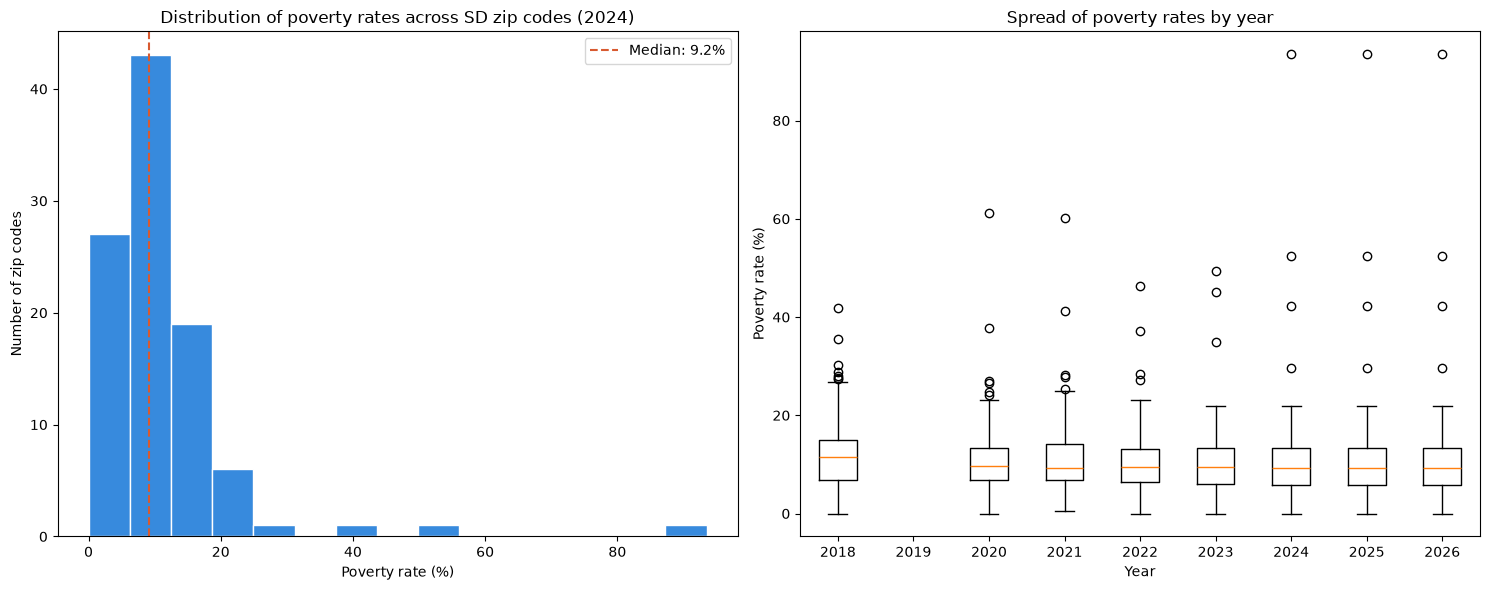

=== 1. POVERTY RATE DISTRIBUTION (2024) ===
count    99.000000
mean     11.594949
std      11.146413
min       0.000000
25%       5.900000
50%       9.200000
75%      13.400000
max      93.500000
Name: Poverty_Rate_Pct, dtype: float64
Skew: 4.86  (mean 11.6% vs median 9.2% -- gap indicates right-skew, driven by a small number of high-poverty, low-population zips)

Excluded 6 zip(s) with 0.0% unemployment: ['91905', '91931', '91963', '91980', '92060', '92136']

Top 5 highest poverty rate:
Zip Code  Poverty_Rate_Pct  Total_Population
   91934              52.5              1200
   91917              42.3               749
   92066              29.7               290
   92113              21.8             48215
   92122              21.2             45411

Bottom 5 lowest poverty rate:
Zip Code  Poverty_Rate_Pct  Total_Population
   92131               3.0             35503
   92067               3.3              7938
   91916               3.8              1710
   92004               4.1

In [25]:
recent_poverty_full = demographics[demographics['Date_Year'] == 2024][
    ['Zip Code', 'Poverty_Rate_Pct', 'Total_Population', 'Unemployment_Rate_Pct']
].dropna(subset=['Poverty_Rate_Pct'])
recent_poverty = recent_poverty_full['Poverty_Rate_Pct']

fig1, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].hist(recent_poverty, bins=15, edgecolor='white', color='#378ADD')
axes[0].axvline(recent_poverty.median(), color='#D85A30', linestyle='--',
                 label=f'Median: {recent_poverty.median():.1f}%')
axes[0].set_xlabel('Poverty rate (%)')
axes[0].set_ylabel('Number of zip codes')
axes[0].set_title('Distribution of poverty rates across SD zip codes (2024)')
axes[0].legend()

box_data = [demographics[demographics['Date_Year'] == y]['Poverty_Rate_Pct'].dropna().values
            for y in sorted(demographics['Date_Year'].unique())]
axes[1].boxplot(box_data, tick_labels=sorted(demographics['Date_Year'].unique()))
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Poverty rate (%)')
axes[1].set_title('Spread of poverty rates by year')

fig1.tight_layout()
fig1.savefig('fig1_poverty_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("=== 1. POVERTY RATE DISTRIBUTION (2024) ===")
print(recent_poverty.describe())
print(f"Skew: {recent_poverty.skew():.2f}  (mean {recent_poverty.mean():.1f}% vs "
      f"median {recent_poverty.median():.1f}% -- gap indicates right-skew, driven "
      f"by a small number of high-poverty, low-population zips)\n")

# Exclude zips where unemployment rate is exactly 0.0 (small-sample
# artifact -- these are tiny-population zips, not literal full employment)
filtered = recent_poverty_full[recent_poverty_full['Unemployment_Rate_Pct'] != 0.0]
print(f"Excluded {len(recent_poverty_full) - len(filtered)} zip(s) with 0.0% unemployment: "
      f"{recent_poverty_full[recent_poverty_full['Unemployment_Rate_Pct'] == 0.0]['Zip Code'].tolist()}")

top5 = filtered.sort_values('Poverty_Rate_Pct', ascending=False).head(5)[
    ['Zip Code', 'Poverty_Rate_Pct', 'Total_Population']
]
bottom5 = filtered.sort_values('Poverty_Rate_Pct', ascending=True).head(5)[
    ['Zip Code', 'Poverty_Rate_Pct', 'Total_Population']
]

print("\nTop 5 highest poverty rate:")
print(top5.to_string(index=False))
print("\nBottom 5 lowest poverty rate:")
print(bottom5.to_string(index=False))
print()

Removed 8 zip(s) with 0.0% unemployment before computing the range/distribution.



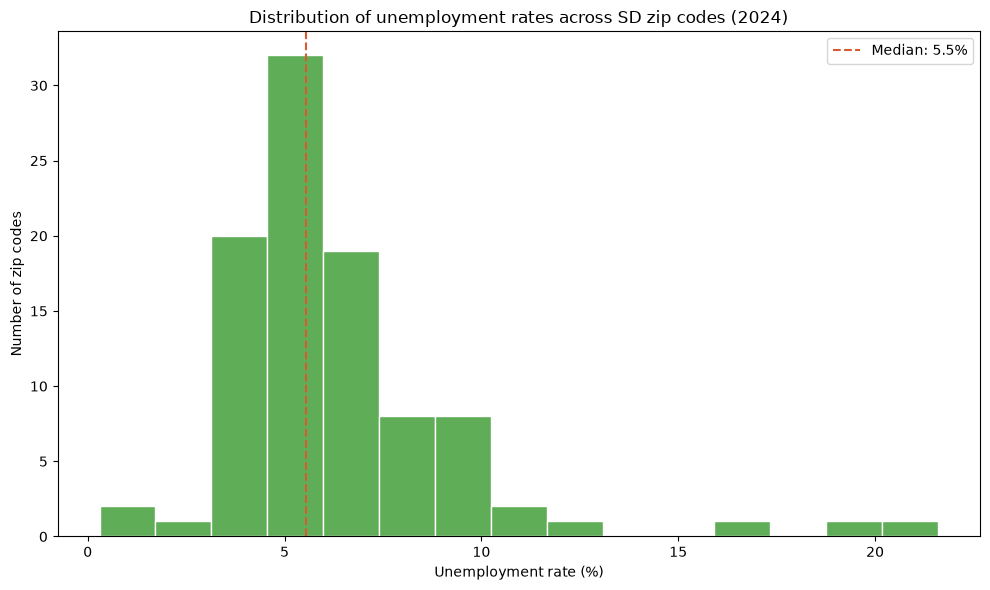

=== 2. UNEMPLOYMENT RATE RANGE (2024) ===
count    96.000000
mean      6.275000
std       3.200164
min       0.300000
25%       4.600000
50%       5.550000
75%       7.200000
max      21.600000
Name: Unemployment_Rate_Pct, dtype: float64
Skew: 2.48

Top 5 highest (check population before treating as reliable):
Zip Code  Unemployment_Rate_Pct  Total_Population
   91962                   21.6              2574
   92093                   20.0              7167
   91934                   17.3              1200
   92173                   12.8             27585
   91911                   11.1             85542

Bottom 5 lowest (0% entries are small-population zips, not full employment):
Zip Code  Unemployment_Rate_Pct  Total_Population
   92070                    0.3               607
   91916                    1.5              1710
   92075                    2.7             11944
   92007                    3.2             11100
   92140                    3.2              2038


In [26]:

# ============================================================
# 2. Range of unemployment rates
# ============================================================
recent_unemployment = demographics[demographics['Date_Year'] == 2024][
    ['Zip Code', 'Unemployment_Rate_Pct', 'Total_Population']
].dropna()

# Remove zips with 0.0% unemployment -- these are small-population zips
# where the ACS estimate rounds/samples to zero, not literal full
# employment, so they'd distort the range and distribution if kept in
n_before = len(recent_unemployment)
recent_unemployment = recent_unemployment[recent_unemployment['Unemployment_Rate_Pct'] != 0.0]
print(f"Removed {n_before - len(recent_unemployment)} zip(s) with 0.0% unemployment "
      f"before computing the range/distribution.\n")

fig2, axes2 = plt.subplots(1, 1, figsize=(10, 6))

axes2.hist(recent_unemployment['Unemployment_Rate_Pct'], bins=15, edgecolor='white', color='#5FAD56')
axes2.axvline(recent_unemployment['Unemployment_Rate_Pct'].median(), color='#D85A30', linestyle='--',
              label=f"Median: {recent_unemployment['Unemployment_Rate_Pct'].median():.1f}%")
axes2.set_xlabel('Unemployment rate (%)')
axes2.set_ylabel('Number of zip codes')
axes2.set_title('Distribution of unemployment rates across SD zip codes (2024)')
axes2.legend()

fig2.tight_layout()
fig2.savefig('fig2_unemployment.png', dpi=150, bbox_inches='tight')
plt.show()

print("=== 2. UNEMPLOYMENT RATE RANGE (2024) ===")
print(recent_unemployment['Unemployment_Rate_Pct'].describe())
print(f"Skew: {recent_unemployment['Unemployment_Rate_Pct'].skew():.2f}\n")
print("Top 5 highest (check population before treating as reliable):")
print(recent_unemployment.sort_values('Unemployment_Rate_Pct', ascending=False)
      .head(5).to_string(index=False))
print("\nBottom 5 lowest (0% entries are small-population zips, not full employment):")
print(recent_unemployment.sort_values('Unemployment_Rate_Pct')
      .head(5).to_string(index=False))

NOTE: 4 zips are top-coded at the rent ceiling ($3501), 13 at the owner-cost ceiling ($4001) -- true costs for these zips may be higher than reported.



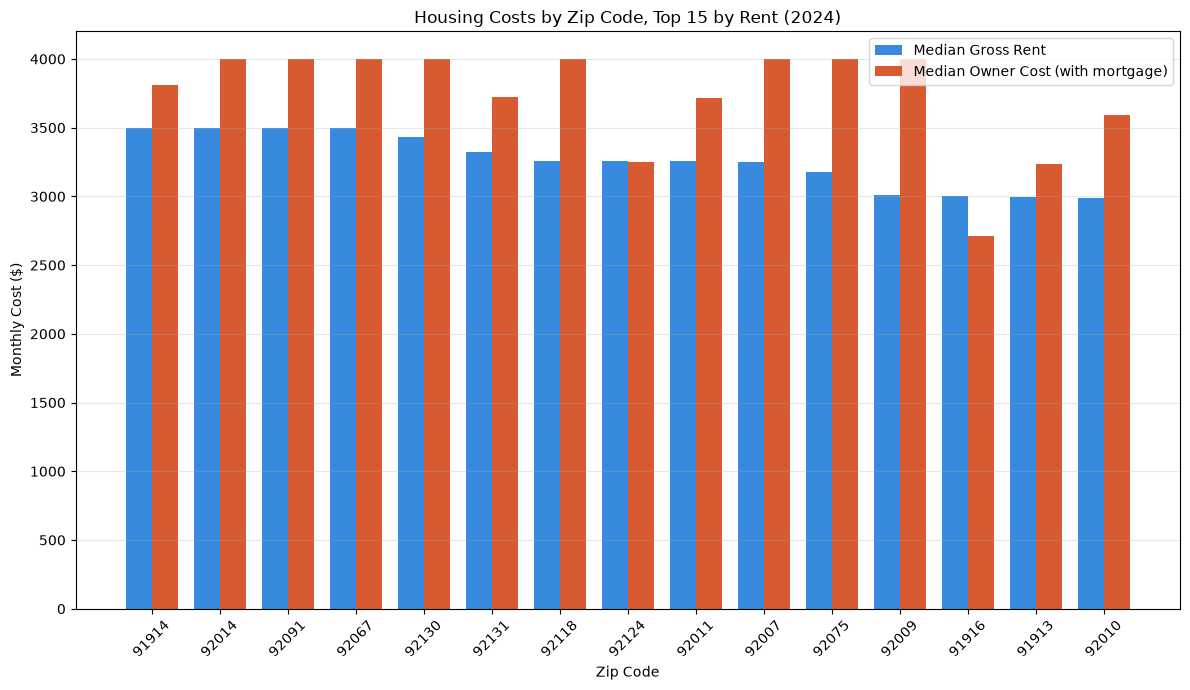

In [27]:
# ============================================================
# 3. Housing cost patterns (NOT a burden ratio -- no income data pulled)
# ============================================================
recent_housing = demographics[demographics['Date_Year'] == 2024][
    ['Zip Code', 'Median_Gross_Rent', 'Median_Monthly_Owner_Cost_With_Mortgage', 'Median_Monthly_Owner_Cost_No_Mortgage']
].dropna(how='all', subset=['Median_Gross_Rent', 'Median_Monthly_Owner_Cost_With_Mortgage'])

rent_cap = recent_housing['Median_Gross_Rent'].max()
owner_cap = recent_housing['Median_Monthly_Owner_Cost_With_Mortgage'].max()
n_rent_capped = (recent_housing['Median_Gross_Rent'] == rent_cap).sum()
n_owner_capped = (recent_housing['Median_Monthly_Owner_Cost_With_Mortgage'] == owner_cap).sum()
print(f"NOTE: {n_rent_capped} zips are top-coded at the rent ceiling (${rent_cap:.0f}), "
      f"{n_owner_capped} at the owner-cost ceiling (${owner_cap:.0f}) -- true costs "
      f"for these zips may be higher than reported.\n")

top15 = recent_housing.sort_values('Median_Gross_Rent', ascending=False).head(15)
x = np.arange(len(top15))
width = 0.38

fig3, ax3 = plt.subplots(figsize=(12, 7))
ax3.bar(x - width/2, top15['Median_Gross_Rent'], width, label='Median Gross Rent', color='#378ADD')
ax3.bar(x + width/2, top15['Median_Monthly_Owner_Cost_With_Mortgage'], width,
        label='Median Owner Cost (with mortgage)', color='#D85A30')
ax3.set_xlabel('Zip Code')
ax3.set_ylabel('Monthly Cost ($)')
ax3.set_title('Housing Costs by Zip Code, Top 15 by Rent (2024)')
ax3.set_xticks(x)
ax3.set_xticklabels(top15['Zip Code'], rotation=45)
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')
fig3.tight_layout()
fig3.savefig('fig3_housing_costs.png', dpi=150, bbox_inches='tight')
plt.show()

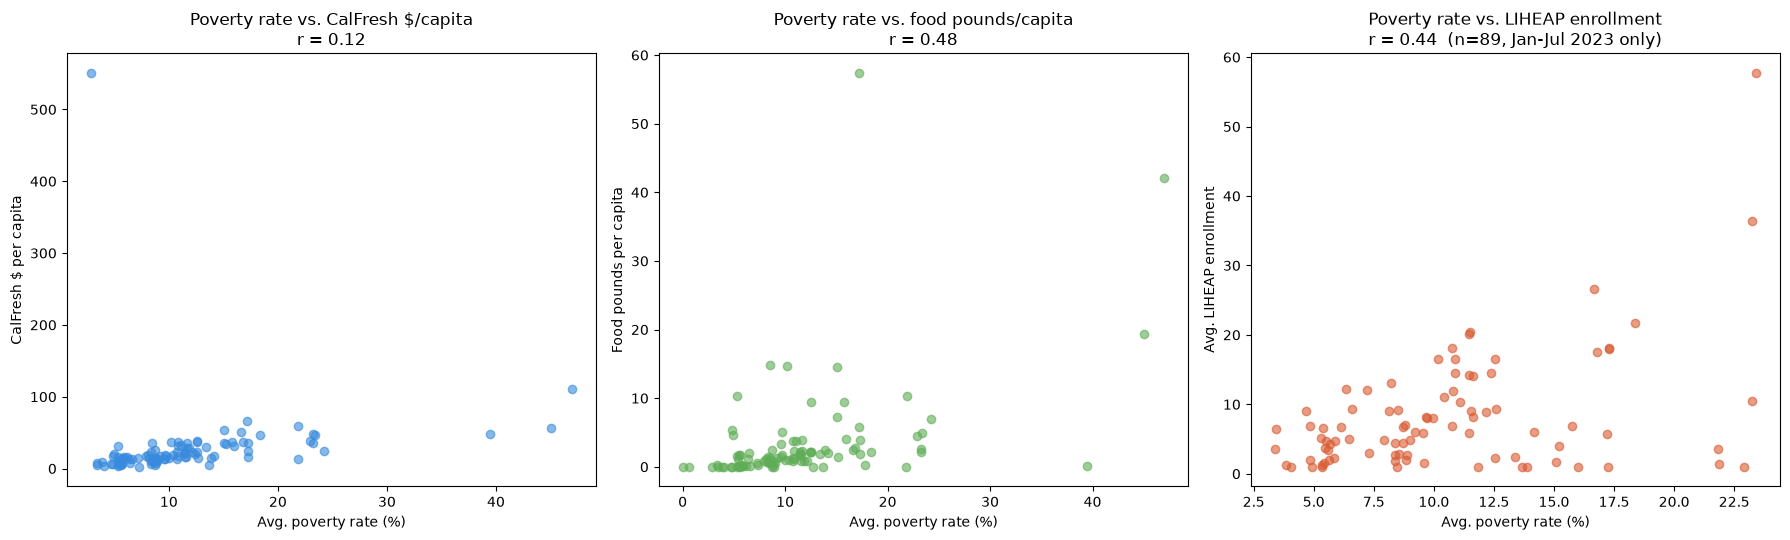

In [28]:
# ============================================================
# 4. Demographic indicators vs. assistance enrollment
# ============================================================
zip_level = merged.groupby('Zip Code').agg(
    Avg_Poverty_Rate=('Poverty_Rate_Pct', 'mean'),
    Avg_Calfresh_Dollars=('Calfresh_Dollars', 'mean'),
    Avg_LIHEAP_Enrollment=('LIHEAP_Enrollment_Count', 'mean'),
    Avg_Total_Pounds=('Total_Pounds_Distributed', 'mean'),
    Avg_Population=('Total_Population', 'mean')
).dropna(subset=['Avg_Poverty_Rate', 'Avg_Population'])

zip_level['Calfresh_Per_Capita'] = zip_level['Avg_Calfresh_Dollars'] / zip_level['Avg_Population']
zip_level['Pounds_Per_Capita'] = zip_level['Avg_Total_Pounds'] / zip_level['Avg_Population']

corr_calfresh_pc = zip_level[['Avg_Poverty_Rate', 'Calfresh_Per_Capita']].dropna().corr().iloc[0, 1]
corr_pounds_pc = zip_level[['Avg_Poverty_Rate', 'Pounds_Per_Capita']].dropna().corr().iloc[0, 1]
liheap_data = zip_level[['Avg_Poverty_Rate', 'Avg_LIHEAP_Enrollment']].dropna()
corr_liheap = liheap_data.corr().iloc[0, 1]

fig4, axes4 = plt.subplots(1, 3, figsize=(18, 5.5))

axes4[0].scatter(zip_level['Avg_Poverty_Rate'], zip_level['Calfresh_Per_Capita'], alpha=0.6, color='#378ADD')
axes4[0].set_xlabel('Avg. poverty rate (%)')
axes4[0].set_ylabel('CalFresh $ per capita')
axes4[0].set_title(f'Poverty rate vs. CalFresh $/capita\nr = {corr_calfresh_pc:.2f}')

axes4[1].scatter(zip_level['Avg_Poverty_Rate'], zip_level['Pounds_Per_Capita'], alpha=0.6, color='#5FAD56')
axes4[1].set_xlabel('Avg. poverty rate (%)')
axes4[1].set_ylabel('Food pounds per capita')
axes4[1].set_title(f'Poverty rate vs. food pounds/capita\nr = {corr_pounds_pc:.2f}')

axes4[2].scatter(liheap_data['Avg_Poverty_Rate'], liheap_data['Avg_LIHEAP_Enrollment'], alpha=0.6, color='#D85A30')
axes4[2].set_xlabel('Avg. poverty rate (%)')
axes4[2].set_ylabel('Avg. LIHEAP enrollment')
axes4[2].set_title(f'Poverty rate vs. LIHEAP enrollment\nr = {corr_liheap:.2f}  (n={len(liheap_data)}, Jan-Jul 2023 only)')

fig4.tight_layout()
fig4.savefig('fig4_demographics_vs_assistance.png', dpi=150, bbox_inches='tight')
plt.show()